# Resumen de la tesis — de los datos al efecto causal de la cochera

Este notebook recorre **toda la tesis en orden**, de forma directa. No vuelve a estimar nada pesado ni llama a la API:
lee los resultados que generan los notebooks de trabajo.

| Paso | Qué responde | Notebook de trabajo |
|---|---|---|
| 1. Datos y auditoría | ¿Con qué avisos trabajamos? | `notebook2_auditoria` |
| 2. EDA resumido | ¿Cómo es el mercado y en qué se diferencian los avisos con y sin cochera? | este notebook |
| 3. Cochera con IA | ¿Cómo se midió la cochera desde el texto? | `notebook2b_extraccion_ia` |
| 4. Modelo causal | ¿Qué se compara y qué se controla? | `notebook3b_efecto_cochera` |
| 5. Soporte común | ¿Hay departamentos comparables? | `notebook3b_efecto_cochera` |
| 6. Efecto principal | ¿Cuánto vale la cochera? | `notebook3b_efecto_cochera` |
| 7. Solidez | ¿Cambia con otras decisiones? ¿Qué tan frágil es? ¿Varía por zona? | `notebook3b_efecto_cochera` |
| 8. Validación | ¿El método funciona con una verdad conocida? | `notebook4_semisintetico` |
| 9. Baños (secundario) | ¿Y un baño adicional? | `notebook3_estimacion_causal` |

**Pregunta de la tesis:** *¿cuánto aumenta el precio de oferta de un alquiler en Lima por incluir cochera, comparando departamentos equivalentes en todo lo demás?*

In [1]:
import warnings, json; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
from causal_utils import *

sns.set_theme(style="whitegrid", context="notebook"); plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_colwidth", 70)
tab = lambda n: pd.read_csv(TAB / f"{n}.csv")
fig = lambda n, w=900: display(Image(filename=str(FIG / f"{n}.png"), width=w))

base = pd.read_csv("../csv/data_causal_base.csv")
d = agregar_cochera(muestra(base))                     # 2 220 avisos ROOFTOP con la variable cochera
d["cochera"] = d["tipo_cochera"].map({"incluida": "Con cochera incluida", "no_tiene": "Sin cochera",
                                      "sin_mencion": "Sin cochera", "costo_extra": "Cochera con costo extra",
                                      "ambigua": "Ambigua"})
print(f"Muestra final: {len(d):,} avisos | {d.distrito.nunique()} distritos | precio mediano S/ {d.precio.median():,.0f}")

Muestra final: 2,220 avisos | 13 distritos | precio mediano S/ 2,625


## 1. Datos y auditoría

Del archivo crudo del scraping a la muestra final, cada exclusión con su motivo.
Las dos reglas nuevas respecto del avance previo son la **deduplicación** y el uso de **solo direcciones exactas (ROOFTOP)**:
la ubicación es el confusor más importante y una dirección aproximada puede errar por cientos de metros.

In [2]:
tab("R1_exclusiones")[["paso", "excluidos", "N restante"]]

,paso,excluidos,N restante
0,Archivo crudo del scraping,0,3739
1,Sin dormitorios/baños/área/precio/distrito,223,3516
2,Duplicados D1 (re-publicación),166,3350
3,Duplicados D2 (publicación cruzada),77,3273
4,G1 geocodificación incoherente (>8 km del distrito),26,3247
5,G2 geocodificación no exacta (distinta de ROOFTOP),967,2280
6,"F1 rangos (dorm>6, área>600, precio/m2 fuera de [8,120])",17,2263
7,"F2 área incoherente (<=2 dorm, 1 baño, >=160 m2)",1,2262
8,F4 precio < 600,8,2254
9,F5 combinación dorm-baños rara (<=3 casos),10,2244


## 2. EDA resumido

### 2.1 El mercado en cifras

In [3]:
res = pd.DataFrame({
    "indicador": ["Precio mensual mediano (S/)", "Área mediana (m²)", "Dormitorios (mediana)", "Baños (promedio)",
                  "Antigüedad mediana (años, informada)", "% con cochera incluida", "% sin cochera",
                  "% cochera con costo extra"],
    "valor": [d.precio.median(), d.area.median(), d.dormitorios.median(), round(d.banos.mean(), 2),
              d.antiguedad.median(), round(100 * (d.tipo_cochera == "incluida").mean(), 1),
              round(100 * d.tipo_cochera.isin(["no_tiene", "sin_mencion"]).mean(), 1),
              round(100 * (d.tipo_cochera == "costo_extra").mean(), 1)]})
res

,indicador,valor
0,Precio mensual mediano (S/),2625.00
1,Área mediana (m²),78.00
2,Dormitorios (mediana),2.00
3,Baños (promedio),1.84
4,"Antigüedad mediana (años, informada)",8.00
5,% con cochera incluida,49.30
6,% sin cochera,43.10
7,% cochera con costo extra,6.80


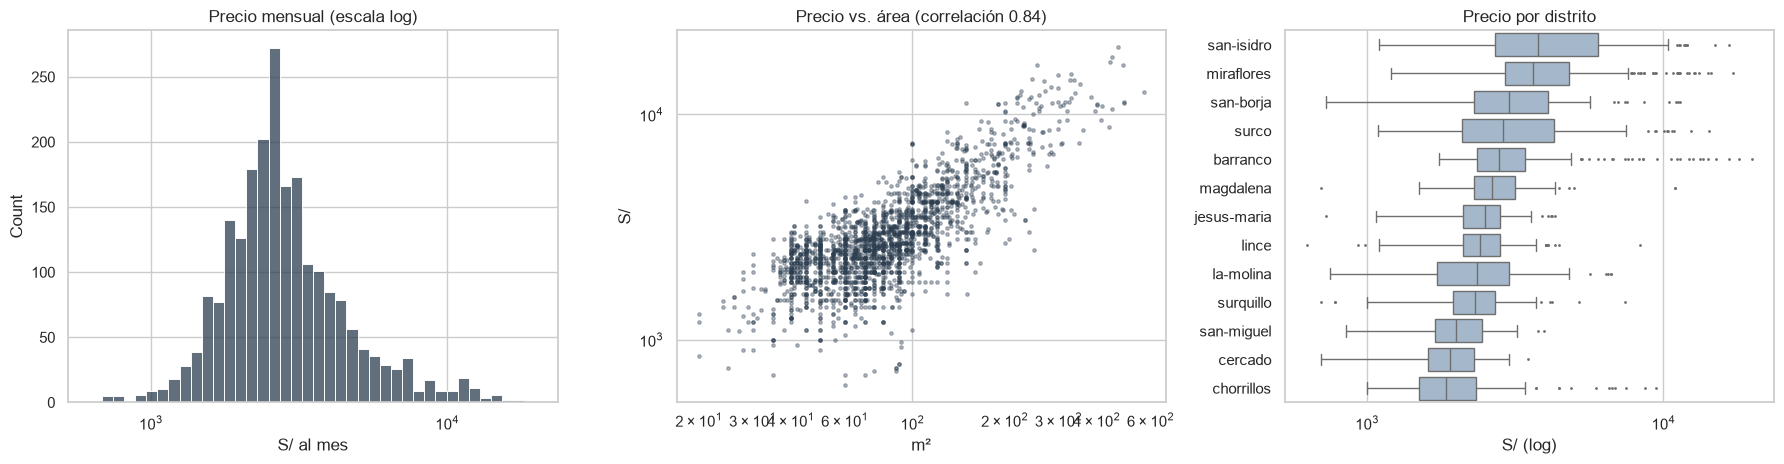

In [4]:
orden = d.groupby("distrito")["precio"].median().sort_values(ascending=False).index
f, ax = plt.subplots(1, 3, figsize=(18, 4.8))
sns.histplot(d["precio"], bins=40, log_scale=True, ax=ax[0], color="#2c3e50")
ax[0].set_title("Precio mensual (escala log)"); ax[0].set_xlabel("S/ al mes")
ax[1].scatter(d["area"], d["precio"], s=6, alpha=.35, color="#2c3e50"); ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_title(f"Precio vs. área (correlación {d[['precio','area']].corr().iloc[0,1]:.2f})"); ax[1].set_xlabel("m²"); ax[1].set_ylabel("S/")
sns.boxplot(data=d, y="distrito", x="precio", order=orden, ax=ax[2], color="#9fb8d1", fliersize=1)
ax[2].set_xscale("log"); ax[2].set_title("Precio por distrito"); ax[2].set_xlabel("S/ (log)"); ax[2].set_ylabel("")
plt.tight_layout(); plt.savefig(FIG / "F0_eda_mercado.png", bbox_inches="tight"); plt.show()

**Lectura.** El precio crece casi proporcionalmente con el área y depende mucho del distrito: Miraflores y San Isidro duplican a Cercado
o Chorrillos. Por eso **área y ubicación son los confusores principales** de cualquier atributo.

### 2.2 Con y sin cochera: ¿en qué se diferencian?

In [5]:
g = d[d.cochera.isin(["Con cochera incluida", "Sin cochera"])]
perfil = (g.groupby("cochera").agg(avisos=("precio", "size"), precio_mediano=("precio", "median"), area_mediana=("area", "median"),
                                    banos_prom=("banos", "mean"), antig_mediana=("antiguedad", "median"),
                                    pct_clase1=("distrito_clase", lambda x: 100 * (x == "clase1").mean()))
           .round(1))
perfil.loc["Diferencia (%)"] = (100 * (perfil.iloc[0] / perfil.iloc[1] - 1)).round(1)
perfil.loc["Diferencia (%)", "avisos"] = np.nan
perfil

,avisos,precio_mediano,area_mediana,banos_prom,antig_mediana,pct_clase1
cochera,,,,,,
Con cochera incluida,1095.0,3200.0,96.0,2.1,9.0,56.0
Sin cochera,956.0,2197.5,65.0,1.6,7.0,31.9
Diferencia (%),NaN,45.6,47.7,31.2,28.6,75.5


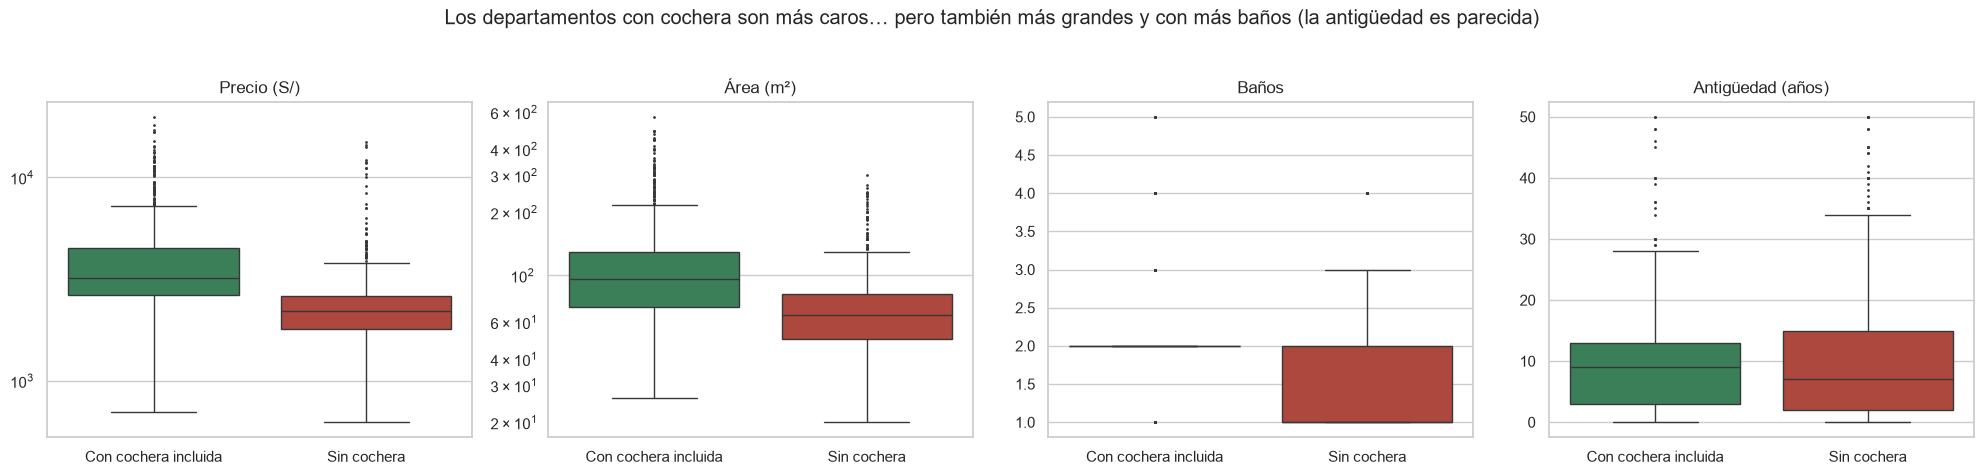

In [6]:
f, ax = plt.subplots(1, 4, figsize=(20, 4.6))
pal = {"Con cochera incluida": "#2e8b57", "Sin cochera": "#c0392b"}
for a, (v, t, lg) in zip(ax, [("precio", "Precio (S/)", True), ("area", "Área (m²)", True), ("banos", "Baños", False),
                              ("antiguedad", "Antigüedad (años)", False)]):
    sns.boxplot(data=g, x="cochera", y=v, hue="cochera", palette=pal, ax=a, fliersize=1, legend=False)
    if lg: a.set_yscale("log")
    a.set_title(t); a.set_xlabel(""); a.set_ylabel("")
plt.suptitle("Los departamentos con cochera son más caros… pero también más grandes y con más baños (la antigüedad es parecida)", y=1.03)
plt.tight_layout(); plt.savefig(FIG / "F0_eda_cochera_perfil.png", bbox_inches="tight"); plt.show()

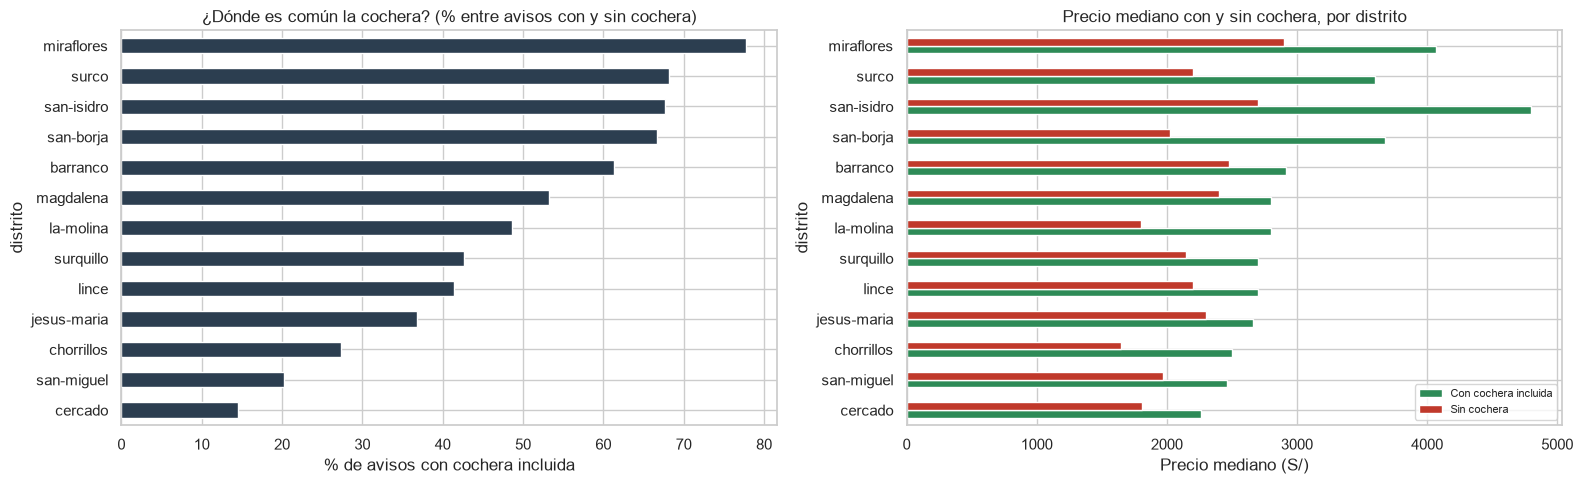

In [7]:
pct = (100 * g.groupby("distrito")["cochera"].apply(lambda x: (x == "Con cochera incluida").mean())).sort_values()
pm = g.pivot_table(index="distrito", columns="cochera", values="precio", aggfunc="median").reindex(pct.index)
f, ax = plt.subplots(1, 2, figsize=(16, 5))
pct.plot.barh(ax=ax[0], color="#2c3e50"); ax[0].set_xlabel("% de avisos con cochera incluida")
ax[0].set_title("¿Dónde es común la cochera? (% entre avisos con y sin cochera)")
pm.plot.barh(ax=ax[1], color=[pal[c] for c in pm.columns]); ax[1].set_xlabel("Precio mediano (S/)")
ax[1].set_title("Precio mediano con y sin cochera, por distrito"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "F0_eda_cochera_distrito.png", bbox_inches="tight"); plt.show()

**Lectura.**
* Sin ajustar, los avisos con cochera cuestan **≈ 46 % más** en la mediana, pero son **≈ 48 % más grandes** y están el doble de veces
  en los distritos más caros. **Esa diferencia bruta mezcla la cochera con el tamaño y la zona**: es justamente lo que el análisis causal separa.
* La cochera es **muy común en Miraflores (78 %), San Isidro y Surco**, y **escasa en Cercado (15 %) y San Miguel (20 %)**.
  En Miraflores y San Isidro, la normativa municipal exige estacionamientos mínimos por vivienda.

In [8]:
ce = d[(d.tipo_cochera == "costo_extra") & d.precio_extra.notna()]
co = pd.read_csv("../csv/cochera_extraccion.csv")
ce = ce.merge(co[["id_aviso", "moneda"]], on="id_aviso", how="left")
pen = ce[ce.moneda == "PEN"]["precio_extra"]
print(f"Avisos que cobran la cochera aparte con monto: {len(ce)} | en soles: {len(pen)} | mediana S/ {pen.median():.0f} "
      f"(rango intercuartil S/ {pen.quantile(.25):.0f}–{pen.quantile(.75):.0f})")

Avisos que cobran la cochera aparte con monto: 110 | en soles: 84 | mediana S/ 250 (rango intercuartil S/ 200–300)


**El propio mercado le pone precio a la cochera:** cuando se cobra aparte, la mediana pedida es de unos **S/ 250 al mes**.
Sirve de referencia para juzgar si el efecto estimado es razonable.

## 3. La cochera medida con IA

La cochera no venía en la base: se leyó en la descripción. Regex → fragmento de ±200 caracteres → `gpt-4.1-mini` con JSON fijo.
Costo total: **0.76 USD**. **Pendiente:** validar con 249 avisos etiquetados a mano.

In [9]:
tab("R8_distribucion")

,tipo,N,%,uso en el análisis
0,ambigua,19,0.855856,excluido
1,costo_extra,150,6.756757,excluido
2,incluida,1095,49.324324,T = 1
3,no_tiene,297,13.378378,T = 0
4,sin_mencion,659,29.684685,T = 0


## 4. Modelo causal: qué se compara

Se comparan **departamentos equivalentes en área, dormitorios, baños, antigüedad y ubicación que solo difieren en tener o no cochera incluida**.
El DAG fija qué se controla (azul) y qué no (precio/m², descendiente del precio). La amenaza principal es la **calidad del edificio** (U), que no se observa.

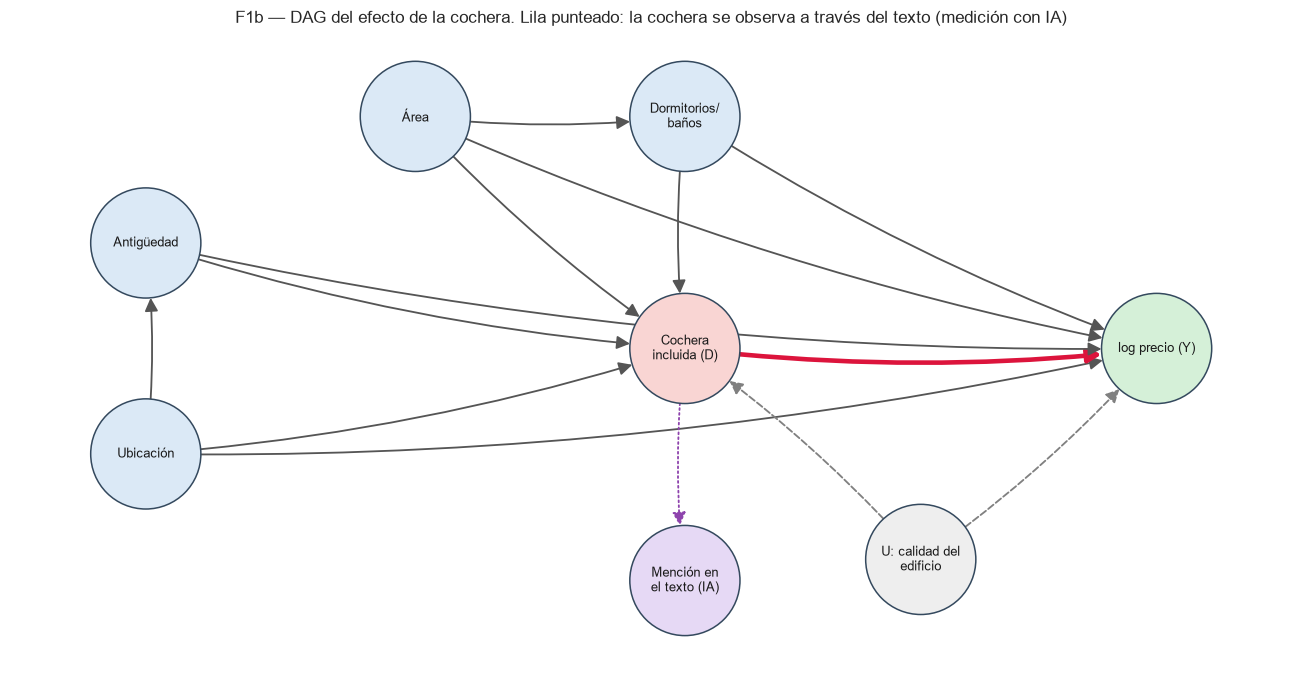

In [10]:
fig("F1b_dag_cochera", 850)

## 5. Soporte común: ¿hay departamentos comparables?

Un modelo predice la probabilidad de tener cochera (propensión). Se conservan los avisos con propensión entre 0.05 y 0.95,
y tras ponderar, los dos grupos quedan **balanceados** (todas las diferencias estandarizadas < 0.05).

,diagnóstico,valor
0,AUC de la propensión (fuera de fold),0.824
1,Log-loss,0.516
2,Brier,0.171
3,"R² de E[Y|D,X] (fuera de fold)",0.824
4,Propensión mínima / máxima,0.004 / 0.992
5,"% fuera de [0.05, 0.95]",5.0 %
6,N en soporte común,"1,949"
7,Tratados / controles en soporte común,"1,046 / 903"


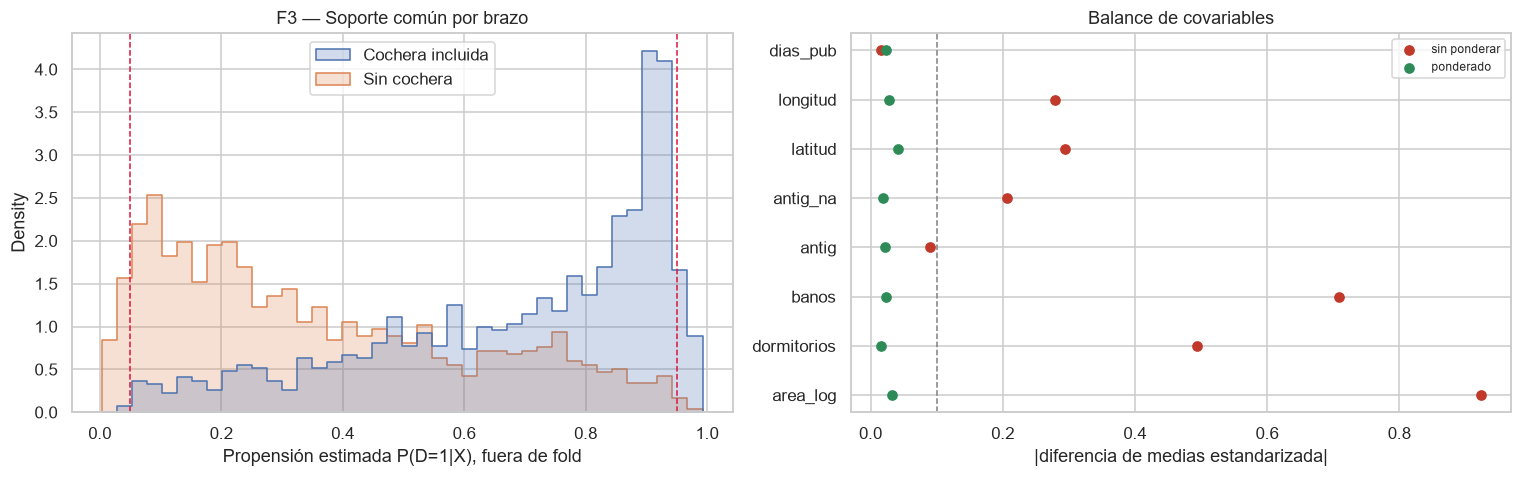

In [11]:
display(tab("R2_soporte")); fig("F3_soporte_cochera", 950)

## 6. Efecto principal

,estimador,N,% efecto,% IC inf,% IC sup,S/ al mes (ref.)
0,Diferencia sin ajustar (OLS),2051,63.0,56.8,69.4,1668.3
1,Hedónico OLS,2051,7.8,5.0,10.6,205.9
2,DML parcialmente lineal (PLR),2051,7.1,4.6,9.6,187.4
3,"DML-IRM, muestra completa",2051,4.3,-2.7,11.9,115.1
4,"DML-IRM, soporte común (principal)",1949,7.5,3.7,11.4,199.0


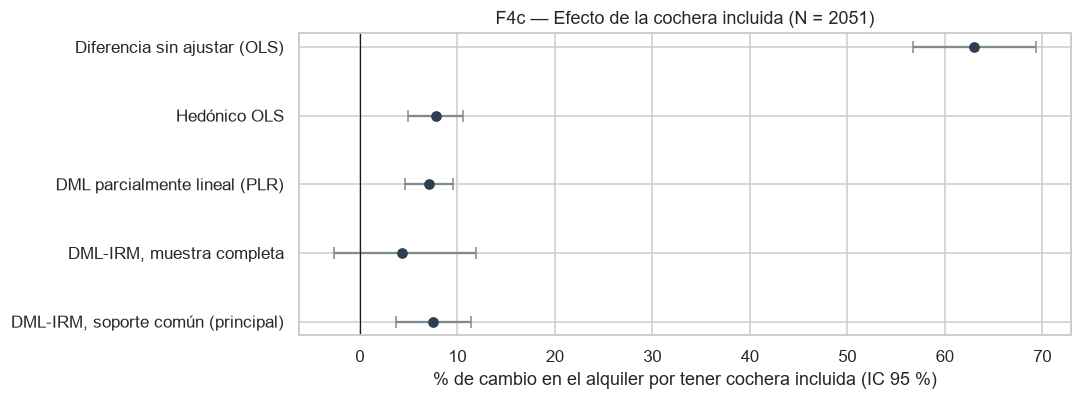

In [12]:
r3 = tab("R3c_principal")[["estimador", "N", "% efecto", "% IC inf", "% IC sup", "S/ al mes (ref.)"]].round(1)
display(r3); fig("F4c_estimadores_cochera", 800)

**Resultado:** tener cochera incluida eleva el precio de oferta en **≈ 7.5 % (IC 95 %: 3.7–11.4 %), unos S/ 199 al mes**.
La diferencia bruta del 63 % era casi toda tamaño y zona. El orden de magnitud es coherente con los S/ 250 que pide el mercado cuando la cobra aparte.

## 7. Solidez del resultado

### 7.1 ¿Qué decisiones cambian el resultado?

In [13]:
tab("R4c_especificaciones")[["código", "especificación", "tipo", "N", "% efecto", "IC95 inf", "IC95 sup"]].round(3)

,código,especificación,tipo,N,% efecto,IC95 inf,IC95 sup
0,C1,Principal,válida,1931,7.592,0.041,0.106
1,C2,Sin área,omite confusor,1972,11.416,0.055,0.161
2,C3,"Sin ubicación (distrito, lat, lon)",omite confusor,1975,21.669,0.157,0.236
3,C4,Sin baños ni dormitorios,omite confusor,1941,9.065,0.051,0.123
4,C5,Sin antigüedad,omite confusor,1930,8.061,0.044,0.111
5,C6,+ precio/m² (descendiente de Y),control inadmisible,1820,-0.456,-0.020,0.011
6,C7,Tratamiento estricto (incluida explícita),medición,547,7.945,0.009,0.143
7,C8,Cochera con costo extra también como D=1,medición,2113,5.287,0.021,0.082
8,C9,+ indicador de descripción cortada,medición,1926,7.437,0.036,0.107
9,P1,Folds y EE por bloque de 1 km,partición,1953,7.659,0.034,0.114


Sin ubicación el efecto se triplica (las cocheras abundan en zonas caras); con el precio/m², que es un control prohibido, desaparece.
Las alternativas de medición se mueven en la dirección esperada.

### 7.2 ¿Varía por zona?

,segmentación,grupo,n,% efecto,p-valor Wald
0,clase de distrito,clase1,876,1.499,0.000
1,clase de distrito,clase2,605,10.250,0.000
2,clase de distrito,clase3,468,17.799,0.000
3,quintil de área,Q1 (25-55 m2),420,11.915,0.348
4,quintil de área,Q2 (56-70 m2),385,10.119,0.348
5,quintil de área,Q3 (70-89 m2),374,4.182,0.348
6,quintil de área,Q4 (90-116 m2),380,5.420,0.348
7,quintil de área,Q5 (117-440 m2),390,7.709,0.348


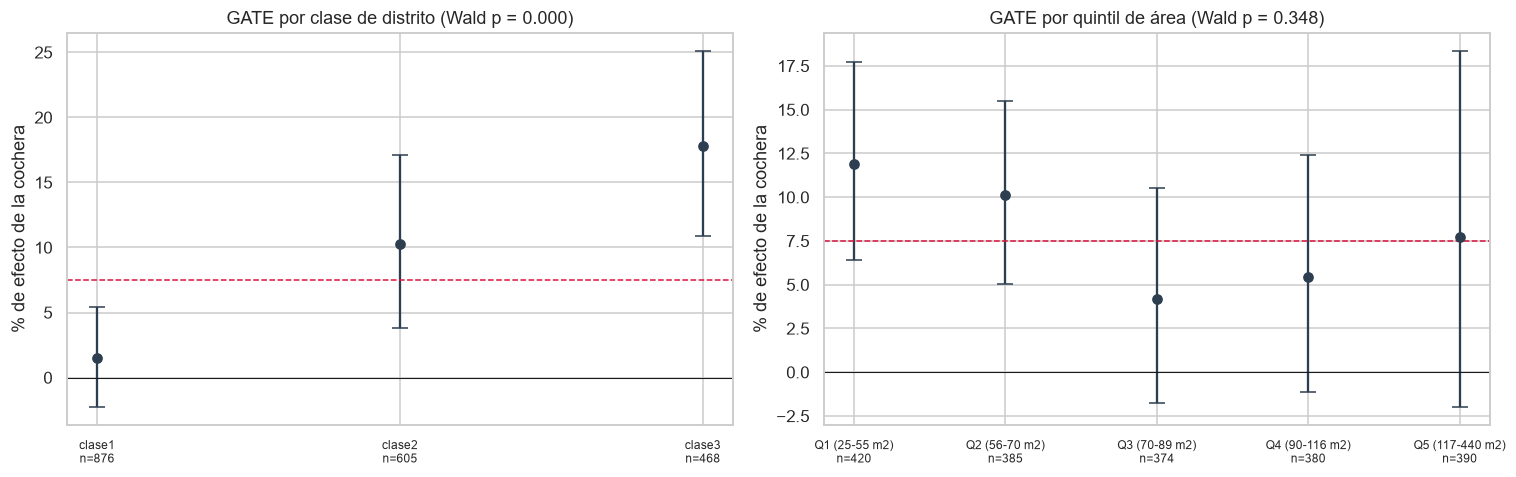

In [14]:
display(tab("R7c_gate")[["segmentación", "grupo", "n", "% efecto", "p-valor Wald"]].round(3)); fig("F7c_heterogeneidad_cochera", 950)

**Sí:** ≈ 1.5 % en los distritos más caros (donde casi todos tienen cochera), ≈ 10 % en la clase2 y ≈ 18 % donde es escasa.

### 7.3 ¿Qué tan frágil es?

,indicador,valor
0,RV (θ → 0),0.105
1,RV_α (límite inferior IC → 0),0.054


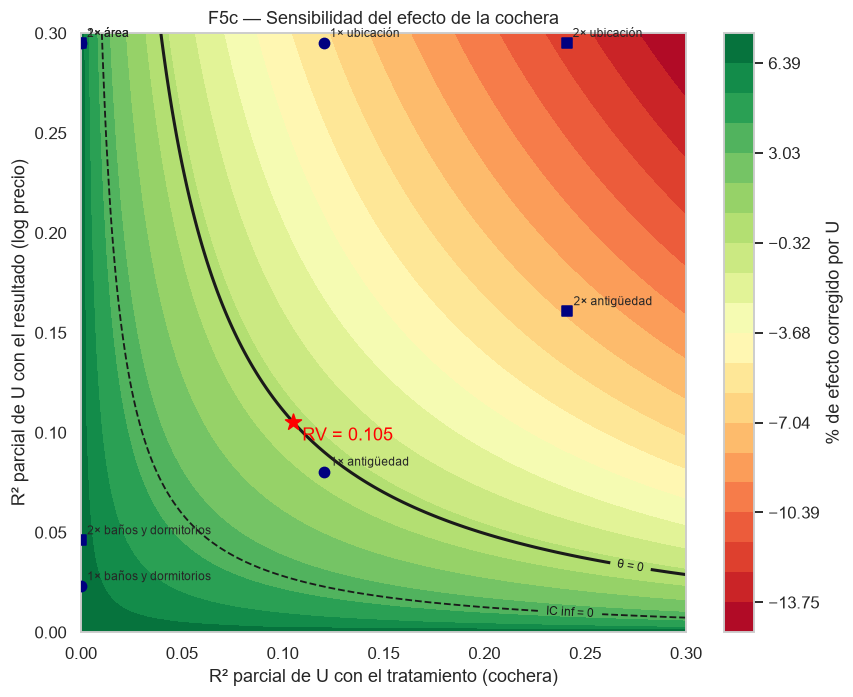

In [15]:
display(tab("R5c_robustez").round(3)); fig("F5c_sensibilidad_cochera", 600)

Un factor oculto que explique ≈ 10 % de la variación residual de la cochera y del precio anularía el efecto; uno tan fuerte como la
antigüedad lo dejaría cerca de cero. **Resultado frágil**, válido bajo los supuestos del DAG.

## 8. Validación con verdad conocida

,escenario,estimador,verdad,sesgo,RMSE,cobertura IC 95 %,long. media IC
0,B1 Binario sin U,Hedónico OLS,0.1,0.000,0.015,94.0,0.058
1,B1 Binario sin U,DML PLR,0.1,-0.004,0.014,95.0,0.055
2,B1 Binario sin U,DML-IRM (soporte común),0.1,-0.004,0.020,96.0,0.081
3,B2 Binario con U moderado,Hedónico OLS,0.1,0.041,0.043,19.0,0.057
4,B2 Binario con U moderado,DML PLR,0.1,0.039,0.042,20.0,0.053
5,B2 Binario con U moderado,DML-IRM (soporte común),0.1,0.042,0.046,45.0,0.078


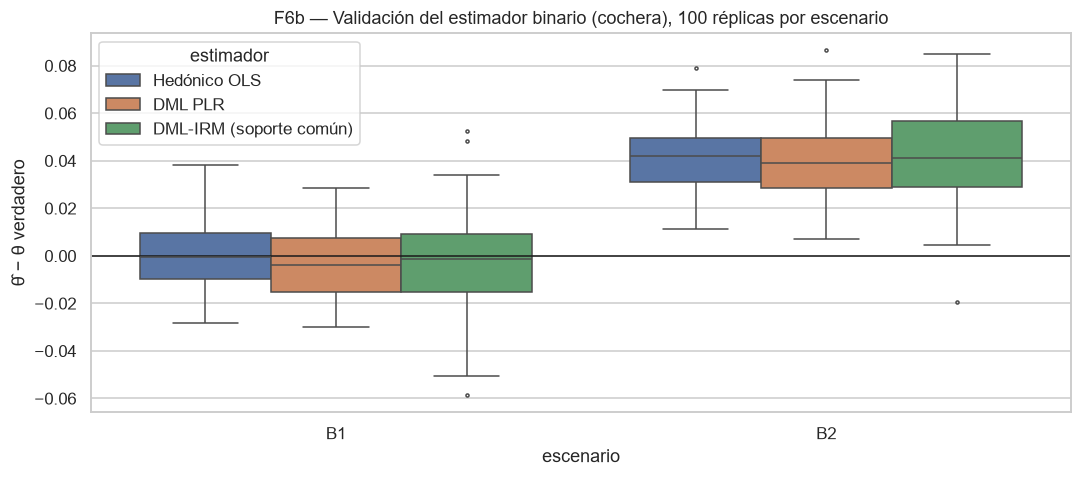

In [16]:
display(tab("R6b_simulacion_binaria").round(3)); fig("F6b_semisintetico_binario", 750)

Sin factor oculto (B1) los métodos aciertan (cobertura 94–96 %). Con un factor oculto (B2) todos se sesgan y la cota de sensibilidad
lo subestima: por eso la fragilidad real (sección 7.3) podría ser mayor.

## 9. Análisis secundario: un baño adicional

In [17]:
tab("R3_principal")[["estimador", "% por baño", "% IC inf", "% IC sup", "S/ al mes (ref.)"]].round(1)

,estimador,% por baño,% IC inf,% IC sup,S/ al mes (ref.)
0,Asociación sin ajustar (OLS),45.7,42.1,49.4,1199.5
1,Hedónico OLS (S1 lineal),7.4,5.1,9.7,193.7
2,"Double ML PLR (HGB, S1)",3.8,1.7,5.9,100.3


Un baño adicional: **≈ 3.8 % (1.7–6.0 %), unos S/ 100 al mes**. En el avance previo la regresión lineal sugería S/ 195–298.

## Conclusión

1. **Observacional:** los avisos con cochera cuestan mucho más, pero casi todo es tamaño y zona.
2. **Causal (bajo los supuestos del DAG):** la cochera incluida eleva el alquiler ≈ 7.5 % (≈ S/ 199 al mes); casi nada donde es estándar y hasta ≈ 18 % donde escasea.
3. **Límites:** confusor de calidad del edificio, medición con IA sin validación humana todavía y cota de sensibilidad optimista.